# 02 — Forward uncertainty (Monte Carlo)

Every card value with a distribution is uncertain: material, probe and interface alike. Fixed values
and control settings are exact. `card.draw(rng)` samples a card, and `card.draw(mean=True)` puts every
distribution at its mean. Each Monte Carlo draw is one complete card set, and every operating point runs
through the same LangGraph graph as in notebook 01. Bands show the 5–95 % range. A draw outside a
card's physical support is dropped and counted, never clipped. A draw whose result is unsupported
has no number (NaN), never zero. The backward path (a particle filter on these same draws) is not
here. Running everything takes a few minutes: about 130,000 graph runs at roughly 1 ms each.

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from langgraph.graph import END, START, StateGraph

from esm_p00 import detector, examples
from esm_p00.cards import ExperimentCard, JunctionCard, PulseCard
from esm_p00.mechanisms import electrostatic, electrostriction, piezoresponse, vegard
from esm_p00.protocols import FrequencySweep, PulseReadout
from esm_p00.state import PointState
from material_state import occupancy

## The graph

The same graph as in notebook 01: an optional state step, four parallel mechanisms, the detector.

In [6]:
MECHANISMS = [vegard, piezoresponse, electrostriction, electrostatic]
names = [m.NAME for m in MECHANISMS]

builder = StateGraph(PointState)
builder.add_node("occupancy", occupancy.node)
for m in MECHANISMS:
    builder.add_node(m.NAME, m.node)
builder.add_node("detector", detector.node)
builder.add_conditional_edges(START, lambda s: "occupancy" if s.get("pulse") is not None else names,
                              ["occupancy", *names])
for name in names:
    builder.add_edge("occupancy", name)
builder.add_edge(names, "detector")                     # the detector waits for all four
builder.add_edge("detector", END)
graph = builder.compile()


def run(cards, experiment, pulse=None):
    """One operating point through the graph; cards holds the material, instrument and junction."""
    return graph.invoke({**cards, "experiment": experiment, "pulse": pulse})


def sweep(card_sets, steps, read):
    """Every card set (rows) at every step (columns) through the graph, keeping only read(output)."""
    return np.array([[read(run(cards, s.experiment, s.pulse)) for s in steps] for cards in card_sets], dtype=float)


def total(out):
    """|1w| of the detector total; NaN when the detector is unsupported."""
    d = out["detector"]
    return abs(d.total["1w"]) if d.is_supported else np.nan


def share(out, mechanism):
    """|1w| of one mechanism's share; NaN when the detector is unsupported."""
    d = out["detector"]
    return abs(d.per_mechanism[mechanism]["1w"]) if d.is_supported else np.nan

## The cards and the draws

In [7]:
def draw_sets(nominal, n, rng, only=None):
    """n drawn card sets, and how many draws fell outside the physical support (dropped, never clipped)."""
    sets, refused = [], 0
    for _ in range(n):
        try:
            sets.append({key: card.draw(rng, only=only) for key, card in nominal.items()})
        except ValueError:
            refused += 1
    return sets, refused


material, probe = examples.licoo2(), examples.afm_probe()
wet = examples.ambient_junction()                  # residual CPD 0 +- 20 mV and a thin water layer
dry = JunctionCard(v_cpd_v=wet.v_cpd_v)            # the same residual CPD, no layer
nominal = {"material": material, "instrument": probe, "junction": wet}
#uncertain_names = [name for card in nominal.values() for name in card.uncertain()]

rng = np.random.default_rng(1)
dry_samples, refused_dry = draw_sets({**nominal, "junction": dry}, 200, rng)
samples, refused = draw_sets(nominal, 200, rng)
#print("uncertain:", ", ".join(uncertain_names))
print(f"{refused_dry + refused} of 400 draws outside the physical support dropped")

1 of 400 draws outside the physical support dropped


## 1. Frequency sweep: the interface

The sweep of notebook 01: 2 mV drive and a 10 mV DC offset. Both card sets carry the same
material, probe and residual CPD; one adds the water layer. The layer takes most of the
voltage before it reaches the sample, which shrinks the Vegard signal. The electrostatic force
acts across the whole junction and does not change. Without a layer, the residual CPD
sometimes pushes Vegard outside its bias window; those draws have no number. The dashed lines
run the mean card: every distribution at its mean. They are not the median of the band, because
the model is nonlinear.

no layer: no number in 26% of draws
water layer: no number in 0% of draws


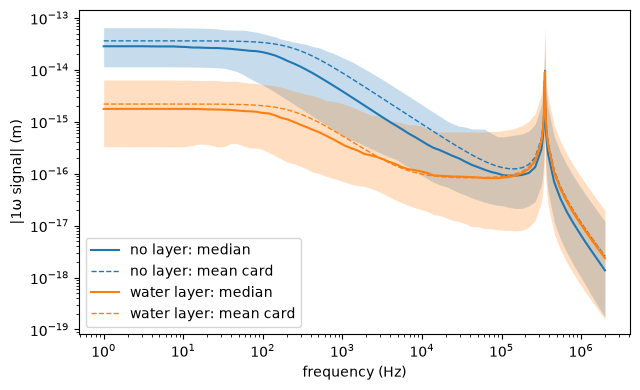

In [8]:
f_cr = probe.contact_resonance_hz.value
frequencies = np.unique(np.concatenate([np.logspace(0, 6.3, 80), np.linspace(0.9, 1.1, 41) * f_cr]))
readout = ExperimentCard(vac_peak_v=0.002, vdc_v=0.01, frequency_hz=1e3, temperature_k=300.0, normal_load_n=50e-9)
steps = FrequencySweep(readout=readout, frequencies_hz=frequencies.tolist()).steps()

fig, ax = plt.subplots(figsize=(6.5, 4))
for label, junction, card_sets, color in (("no layer", dry, dry_samples, "C0"), ("water layer", wet, samples, "C1")):
    y = sweep(card_sets, steps, total)
    low, median, high = np.nanpercentile(y, [5, 50, 95], axis=0)
    mean_card = {key: card.draw(mean=True) for key, card in {**nominal, "junction": junction}.items()}
    ax.fill_between(frequencies, low, high, color=color, alpha=0.25, lw=0)
    ax.loglog(frequencies, median, color=color, label=f"{label}: median")
    ax.loglog(frequencies, sweep([mean_card], steps, total)[0], "--", color=color, lw=1, label=f"{label}: mean card")
    print(f"{label}: no number in {np.isnan(y).any(axis=1).mean():.0%} of draws")
ax.set_xlabel("frequency (Hz)")
ax.set_ylabel("|1ω signal| (m)")
ax.legend(loc="lower left")
fig.tight_layout()

## 2. Which parameter matters where

The sweep with the water layer, drawing one parameter at a time and holding the others at
nominal. The curve is the width of that parameter's 5–95 % band.

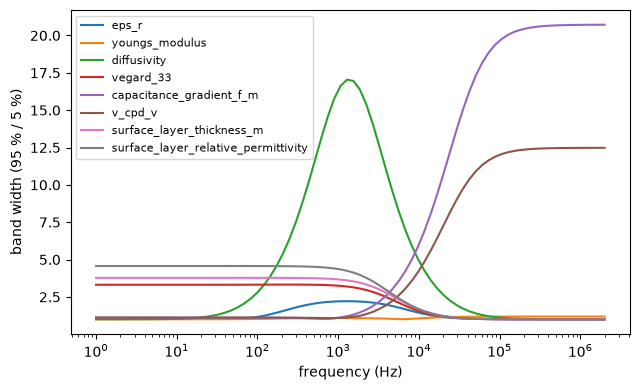

In [5]:
fig, ax = plt.subplots(figsize=(6.5, 4))
for name in uncertain_names:
    one, _ = draw_sets(nominal, 80, rng, only={name})
    low, high = np.nanpercentile(sweep(one, steps, total), [5, 95], axis=0)
    ax.semilogx(frequencies, high / low, label=name)
ax.set_xlabel("frequency (Hz)")
ax.set_ylabel("band width (95 % / 5 %)")
ax.legend(loc="upper left", fontsize=8)
fig.tight_layout()

## 3. Pulse, then relaxation

This uses the water layer, so only a fraction η of the pulse reaches the sample; hence 1 V for 0.1 s.
The readout is off-field at the contact resonance, with a 1 ms window. Each draw is divided by its
own untouched value, so the bands show the uncertainty in the shape of the recovery: its depth comes
from η and its time from τ = a²/4D. Two bands are shown: the Vegard share (what the material does)
and the total (what the detector sees). One graph run per point gives both, together with the state's
checks.

state: readout window too long in 42%, pulse too short in 20% of draws x delays


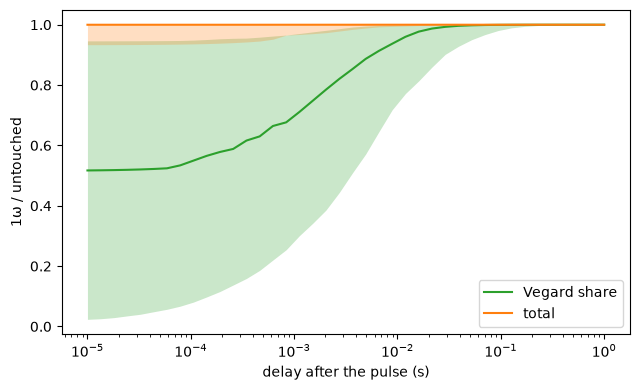

In [6]:
readout_off = ExperimentCard(vac_peak_v=0.002, vdc_v=0.0, frequency_hz=f_cr, temperature_k=300.0, normal_load_n=50e-9)
delays = np.logspace(-5, 0, 40)
protocol = PulseReadout(readout=readout_off, delays_s=delays.tolist(),
                        pulse=PulseCard(pulse_v=1.0, pulse_s=0.1, readout_s=1e-3))
steps = protocol.steps()


def relaxation(out):
    """Total and Vegard share, and the two state checks that the pulse settings can fail."""
    failed = {c.name for c in out["state_report"].failed_checks} if "state_report" in out else set()
    return total(out), share(out, "vegard"), "readout_over_tau" in failed, "pulse_D_over_a2" in failed


after = sweep(samples, steps, relaxation)                                       # draws x delays x 4
before = sweep(samples, [steps[0].model_copy(update={"pulse": None})], relaxation)

fig, ax = plt.subplots(figsize=(6.5, 4))
for label, k, color in (("Vegard share", 1, "C2"), ("total", 0, "C1")):
    low, median, high = np.nanpercentile(after[:, :, k] / before[:, :, k], [5, 50, 95], axis=0)
    ax.fill_between(delays, low, high, color=color, alpha=0.25, lw=0)
    ax.semilogx(delays, median, color=color, label=label)
ax.set_xlabel("delay after the pulse (s)")
ax.set_ylabel("1ω / untouched")
ax.legend(loc="lower right")
fig.tight_layout()
print(f"state: readout window too long in {after[:, :, 2].mean():.0%}, "
      f"pulse too short in {after[:, :, 3].mean():.0%} of draws x delays")

## Reading the results

- **The interface.** The water layer takes most of the voltage (η ≈ 0.02–0.2), so the Vegard
  plateau drops about 15×. The electrostatic force acts across the whole junction and is unchanged,
  so from the contact resonance upward both card sets agree.
- **No number.** Without a layer, the ±20 mV residual CPD puts Vegard outside its bias window in a
  quarter of the draws. Those draws have no number. The layer divides the bias too, so every
  water-layer draw stays inside the window.
- **Which parameter matters:**
  - Below f_c: the layer thickness and permittivity, and β₃₃. εr nearly cancels there, because
    η ∝ 1/√εr while the plateau ∝ √εr.
  - Around 1 kHz: D.
  - From the resonance upward: the electrostatic force, set by C_g and the residual CPD.
- **The relaxation.** The Vegard share recovers on τ, and its depth and time spread with η and D.
  The total at the resonance barely moves, because there the electrostatic force from the residual
  CPD dominates. The ionic signal is real but hidden.
- **Pulse settings.** They fit only part of the D range: the readout window is too long when D is
  large, and the pulse is too short when D is small. Those draws are counted, not hidden.